In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

# Gaussian Repulsion — Moving Obstacle

The Gaussian center circles the tip spring's fixed target (radius 10 cm) while the
tip spring (`lin_seg3`) tries to hold its reference at the origin, for two spring
stiffnesses: k = 2 N/m and k = 20 N/m.

**Goal:** overlay the end-effector path against the moving Gaussian goal, colored by
time, to compare how much the softer spring gets dragged along by the repulsion versus
the stiffer spring holding its ground.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection
import os

In [3]:

def load_circle_window(path: str):
    """Return (t, ee_xy, gauss_xy) arrays trimmed to the circling phase."""
    d = np.load(path)
    t        = d['t']
    goal     = d['goal']      # (n, N_VC, 3)
    comp_pos = d['comp_pos']  # (n, N_VC, 3)

    # Circle starts when |gauss_goal_y| first exceeds 2 mm, ends when it last does
    gauss_goal_y = goal[:, 1, 1]
    mask = np.abs(gauss_goal_y) > 0.002
    idx_start = np.where(mask)[0][0]
    idx_end   = np.where(mask)[0][-1]

    sl = slice(idx_start, idx_end + 1)
    t_w        = t[sl] - t[idx_start]          # zero-based time
    ee_xy      = comp_pos[sl, 0, :2]           # (n, 2)  lin_seg3 end-effector
    gauss_xy   = goal[sl, 1, :2]               # (n, 2)  gaussian goal

    return t_w, ee_xy, gauss_xy


def make_segments(xy: np.ndarray):
    """Convert (n, 2) path into (n-1, 2, 2) line segments for LineCollection."""
    pts = xy.reshape(-1, 1, 2)
    return np.concatenate([pts[:-1], pts[1:]], axis=1)


def draw_panel(ax, t, ee_xy, gauss_xy, title: str, show_ylabel=True, cmap_name='coolwarm'):
    cmap = plt.colormaps[cmap_name]
    norm = mcolors.Normalize(vmin=0, vmax=t[-1])

    # Reference circle
    theta = np.linspace(0, 2 * np.pi, 300)
    ax.plot(0.10 * np.cos(theta), 0.10 * np.sin(theta),
            '--', color='gray', linewidth=0.8, alpha=0.5, label='R=10 cm ref')

    # Origin
    ax.plot(0, 0, 'k+', markersize=8, markeredgewidth=1.5, label='Origin')

    # Gaussian goal path
    segs_g = make_segments(gauss_xy)
    lc_g = LineCollection(segs_g, cmap=cmap, norm=norm,
                          linewidth=1.0, alpha=0.45, zorder=2)
    lc_g.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_g)
    # ghost handle for legend
    ax.plot([], [], color=cmap(0.5), linewidth=1.0, alpha=0.55, label='Gauss goal')

    # End-effector path -- color encodes time, see the shared colorbar
    segs_e = make_segments(ee_xy)
    lc_e = LineCollection(segs_e, cmap=cmap, norm=norm,
                          linewidth=1.8, zorder=3)
    lc_e.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_e)

    # In-panel label instead of a title -- the only thing telling the two panels apart
    ax.text(0.03, 0.97, title, transform=ax.transAxes, ha='left', va='top',
            fontsize=plt.rcParams['axes.labelsize'], fontweight='bold')
    ax.set_xlabel('x [m]')
    if show_ylabel:
        ax.set_ylabel('y [m]')
    ax.set_aspect('equal')
    ax.grid(GRID)

    lim = 0.16
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    return lc_e  # return for shared colorbar


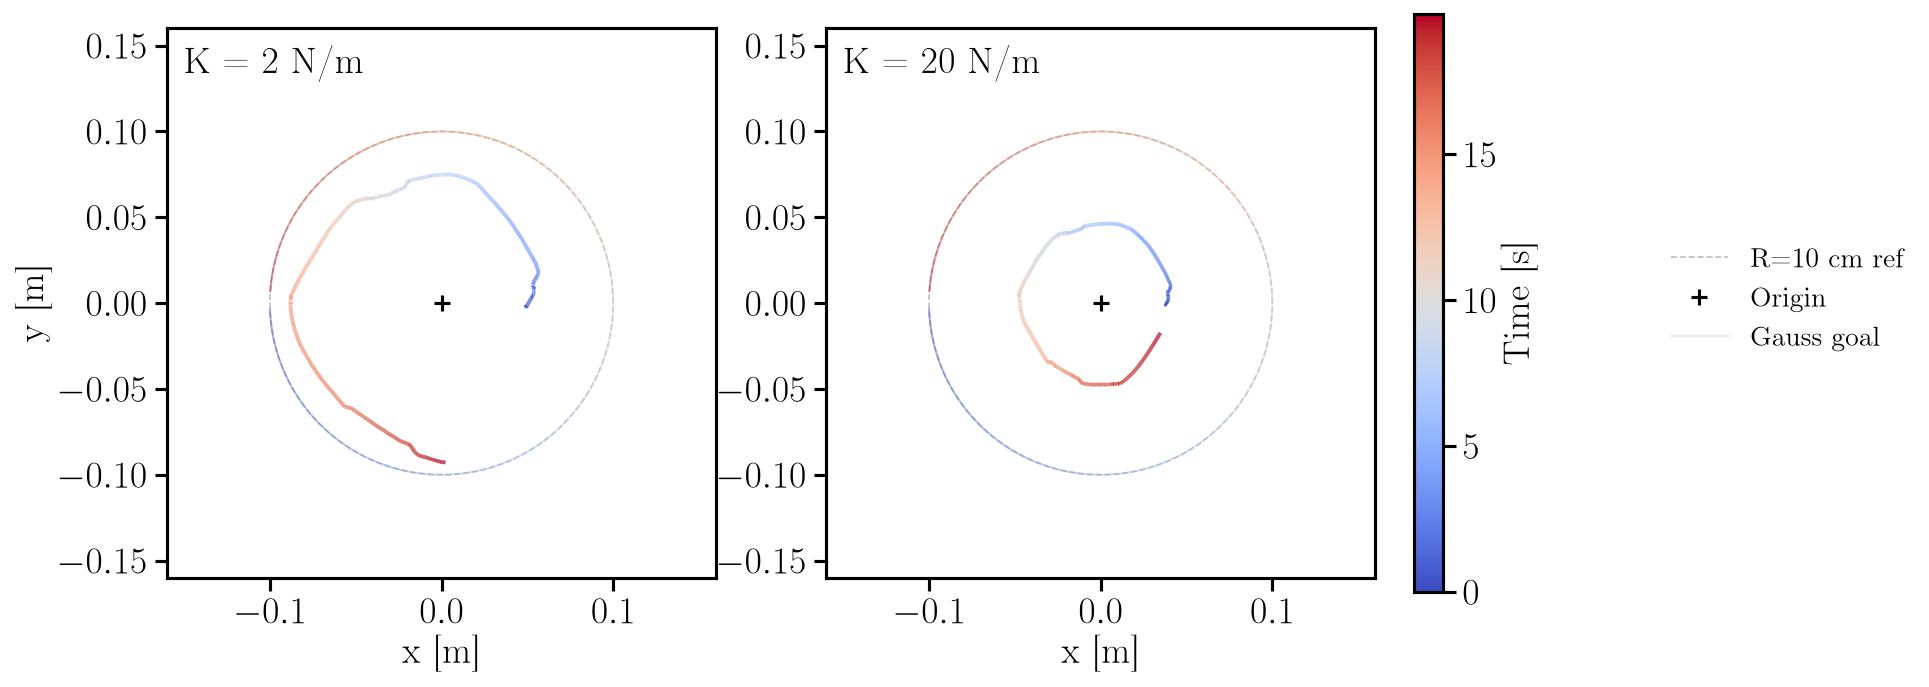

Saved → outputs\moving_gauss\xy_circle_comparison.pdf


In [4]:

files = {
    'K = 2 N/m':  os.path.join('outputs', 'moving_gauss', 'k2_moving_gauss.npz'),
    'K = 20 N/m': os.path.join('outputs', 'moving_gauss', 'k20_moving_gauss.npz'),
}

# ---- size / aspect for THIS graph only ----
W_IN   = 11.0   # inches -- width for both panels + colorbar + legend; the
                # deliberate choice, so the fixed 18pt font reads at the
                # intended size once this is fixed
ASPECT = 5 / 11
H_IN   = W_IN * ASPECT

fig, axes = plt.subplots(1, 2, figsize=(W_IN, H_IN))

last_lc = None
handles, labels = None, None

for i, (ax, (title, path)) in enumerate(zip(axes, files.items())):
    t, ee_xy, gauss_xy = load_circle_window(path)
    lc = draw_panel(ax, t, ee_xy, gauss_xy, title, show_ylabel=(i == 0))
    last_lc = lc
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

# Shared colorbar (time axis)
cbar = fig.colorbar(last_lc, ax=axes, orientation='vertical',
                    fraction=0.025, pad=0.03, label='Time [s]')

# One legend for both panels (identical content, so drawn once) -- placed just
# past the colorbar with room to breathe, instead of cramped into each panel's corner.
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.03, 0.5),
          frameon=False, borderaxespad=0)

out = os.path.join('outputs', 'moving_gauss', 'xy_circle_comparison.pdf')
fig.savefig(out)
plt.show()
print(f"Saved → {out}")
